# 5.4 Trying AMCL in ROS2

After the previous notebook, we are now quite knowledgeable about how Monte Carlo Localization works and all the ideas that underpin it. However, the implementation we worked with is, of course, kind of a simple one. More production-ready versions of the Monte Carlo Localization algorithm include additional techniques, such as *adapting the number of particles* or *injecting random particles* when the robot gets lost.

One such implementation, very widely used in real robotics applications, is **[AMCL](https://docs.nav2.org/jazzy/configuration_and_development/configuration_guide/others/configuring_amcl/)** (which stands for *Adaptive* Monte Carlo Localization). Despite these extra techniques, at its core, AMCL is essentially the same method we are already familiar with. But, how well does it work? Well, luckily for us, a version of AMCL is included in **[Nav2](https://docs.nav2.org/)**, the navigation stack of ROS2, so we can quite easily test it on a simulated robot.

By the end of this notebook you will be able to run AMCL on a simulated robot, tell which data it uses and what it publishes, look at its particles and at the uncertainty of its estimate, explain how it gets lost and how it recovers, and see how many particles it needs. Optionally, you will also use its estimate to make the robot navigate on its own with Nav2.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-rviz.png" width="1100" alt="">
  <figcaption>Fig. 1. The AMCL demo of this notebook in RViz2. Left: the map of the warehouse, the laser scan, the pose estimated by AMCL (green arrow) and the pose given by the odometry alone (blue arrow), which has drifted away. Right: zoom on the robot at another moment, with the particles of AMCL and the uncertainty of its estimate, both in position (magenta ellipse) and in orientation (yellow cone).</figcaption>
</figure>

## 5.4.1 How to work with this notebook

**This notebook is not meant to be run.** ROS2 runs on your own machine, so this notebook plays the role of a **lab guide and report**: keep it open while you work on your terminals, and write your answers back into it:

1. **Commands**: paste the command you used (and, when asked, its output) into the markdown code blocks below.
2. **Screenshots**: a capture of RViz2 or of a terminal.

**Assumed setup.** Ubuntu 24.04, ROS2 Jazzy and MVSim (installed as a ROS2 package), plus **Nav2**, which includes AMCL, and `xterm`, a terminal emulator that the demo uses to open a window for driving the robot:

```bash
sudo apt install ros-jazzy-navigation2 ros-jazzy-nav2-bringup xterm
```

The demo lives in the `robotics_ws` folder of this repository, a ROS2 workspace with several packages that we have to build. From the root of the workspace:

```bash
cd robotics_ws
sudo rosdep init   # only the first time you use rosdep in your computer
rosdep update
rosdep install --from-paths src   # installs any dependency of the packages still missing
colcon build --symlink-install
```

Lastly, remember that you need to set up the workspace in every new terminal where you want to use its packages:

```bash
source install/setup.bash
```

*Tip: the robot is driven from a small `xterm` window with the arrow keys (each key press increases or decreases the linear or angular speed), the space bar stops it and `p` pauses the program. Click on that window before using the keys, and drive gently: if the robot crashes into something, its odometry, and maybe AMCL too, will get confused.*

## 5.4.2 The demo

The package `particle_filter_demo` of the workspace has a prepared example to test AMCL. It launches:

- **MVSim**, simulating a [Clearpath Jackal](https://clearpathrobotics.com/jackal-small-unmanned-ground-vehicle/) robot with a 2D laser scanner in a warehouse. We launch it in *headless* mode, that is, with no GUI of its own: we will watch everything in RViz2.
- **`odom_simulator`**, which computes the odometry of the robot by integrating the velocity commands sent to it. The Jackal is a skid-steered robot, so its wheels slip, especially when turning, and the robot does not move exactly as commanded. This odometry is quite accurate when driving straight, but drifts **a lot** when turning (or when the robot crashes into something), much more than a real one, which makes the effect of AMCL easy to see.
- **`map_server`**, a node of Nav2 that loads the map of the warehouse from a file and publishes it.
- **`amcl`**, the AMCL node of Nav2.
- **`keyboard_control`**, in an `xterm` window, to drive the robot with the arrow keys (the window must have the focus).
- **RViz2** (Fig. 2), with these displays (see also Fig. 1):
  - `Map` and `LaserScan`: the map and the current scan $\mathbf{z}_t$.
  - `pose_AMCL` and `particles_AMCL`: the pose estimated by AMCL (green arrow), its uncertainty (magenta ellipse and yellow cone) and its particles $\mathbf{x}_t^{[i]}$.
  - `pose_Odometry`: the pose given by the odometry alone (blue arrow).
  - `pose_GT`: the true pose of the robot, the *ground truth* (red arrow). It is disabled by default: a real robot does not know it!

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-launched.png" width="1100" alt="">
  <figcaption>Fig. 2. The demo right after launching it: RViz2, with its <i>Displays</i> panel on the left, and the <code>xterm</code> window to drive the robot (bottom right).</figcaption>
</figure>

### **<span style="color:green"><b><i>ASSIGNMENT 1: Launching the demo</i></b></span>**

**What to do?**

1. Launch the demo (and wait a few seconds, the first time MVSim has to download some 3D models):

```bash
ros2 launch particle_filter_demo demo_warehouse.launch.py
```

   Drive the robot around for a while, and include a **screenshot** of RViz2.

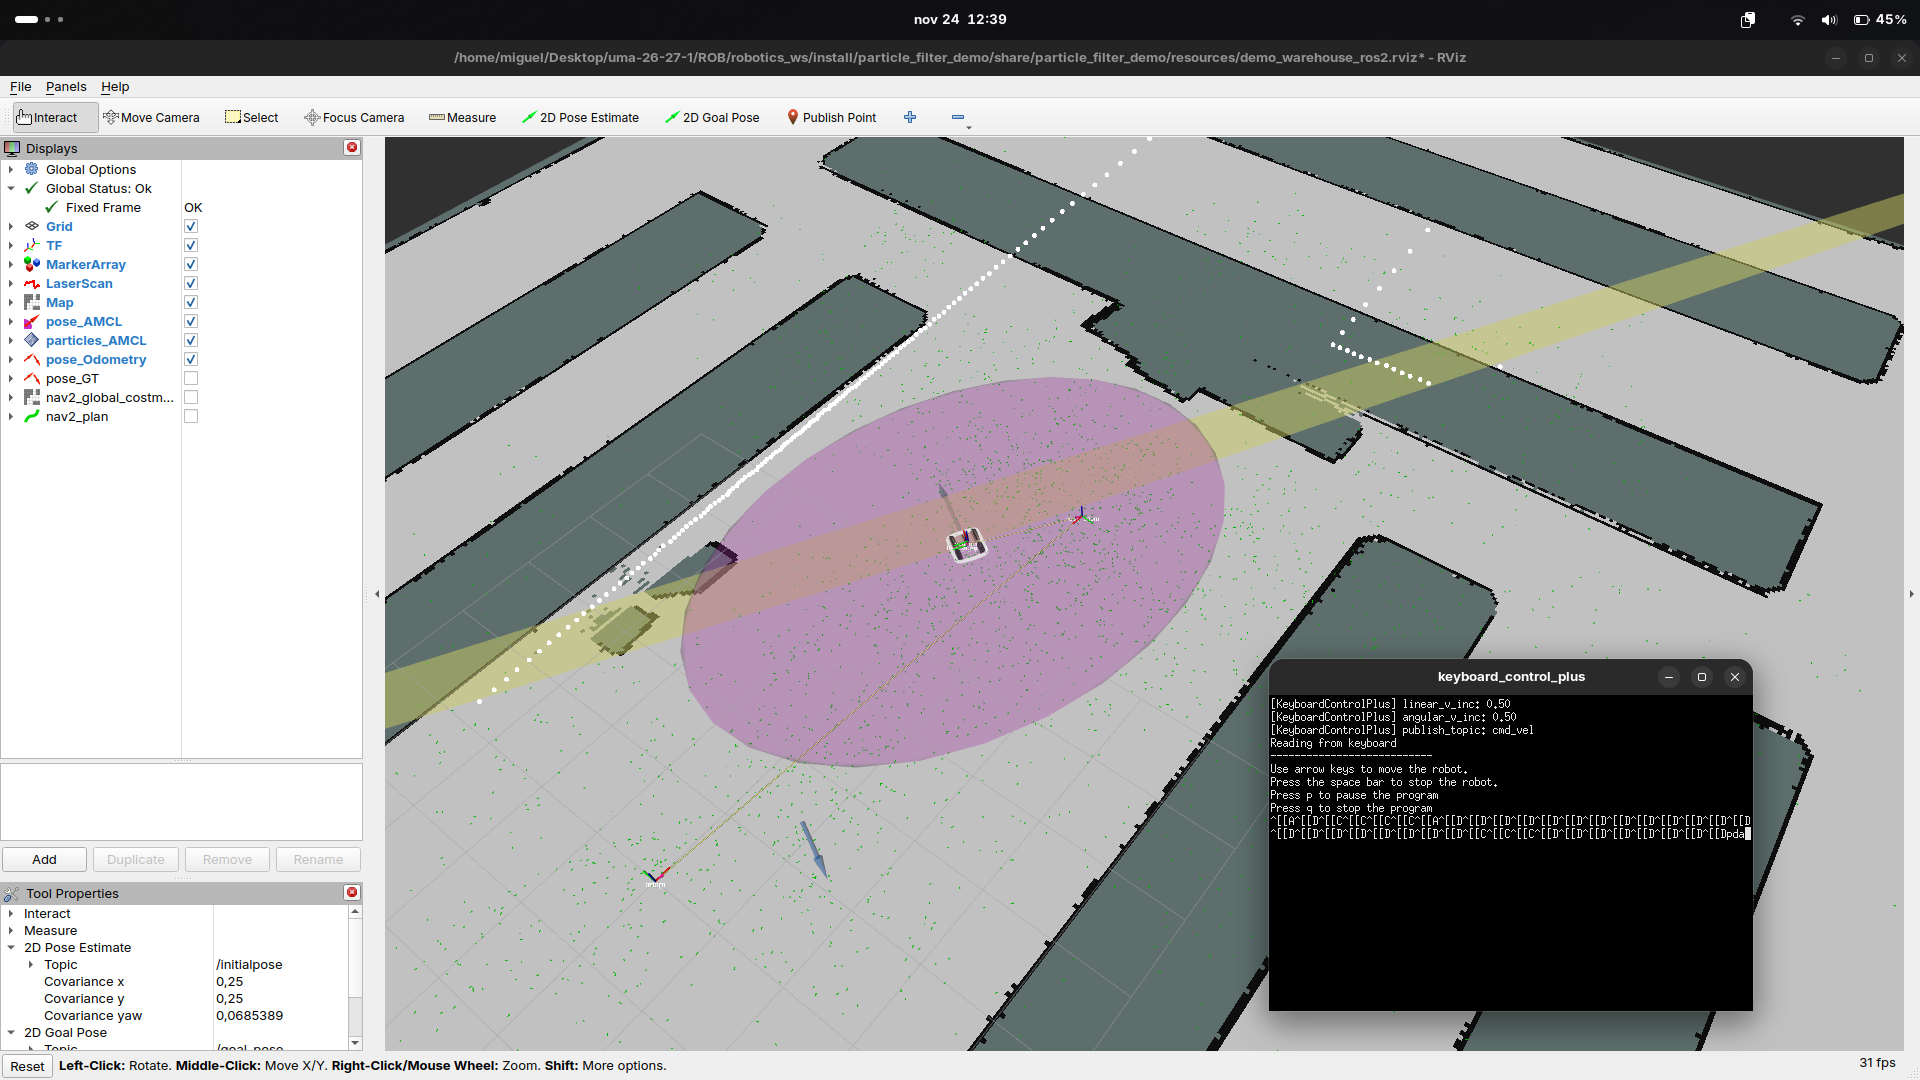
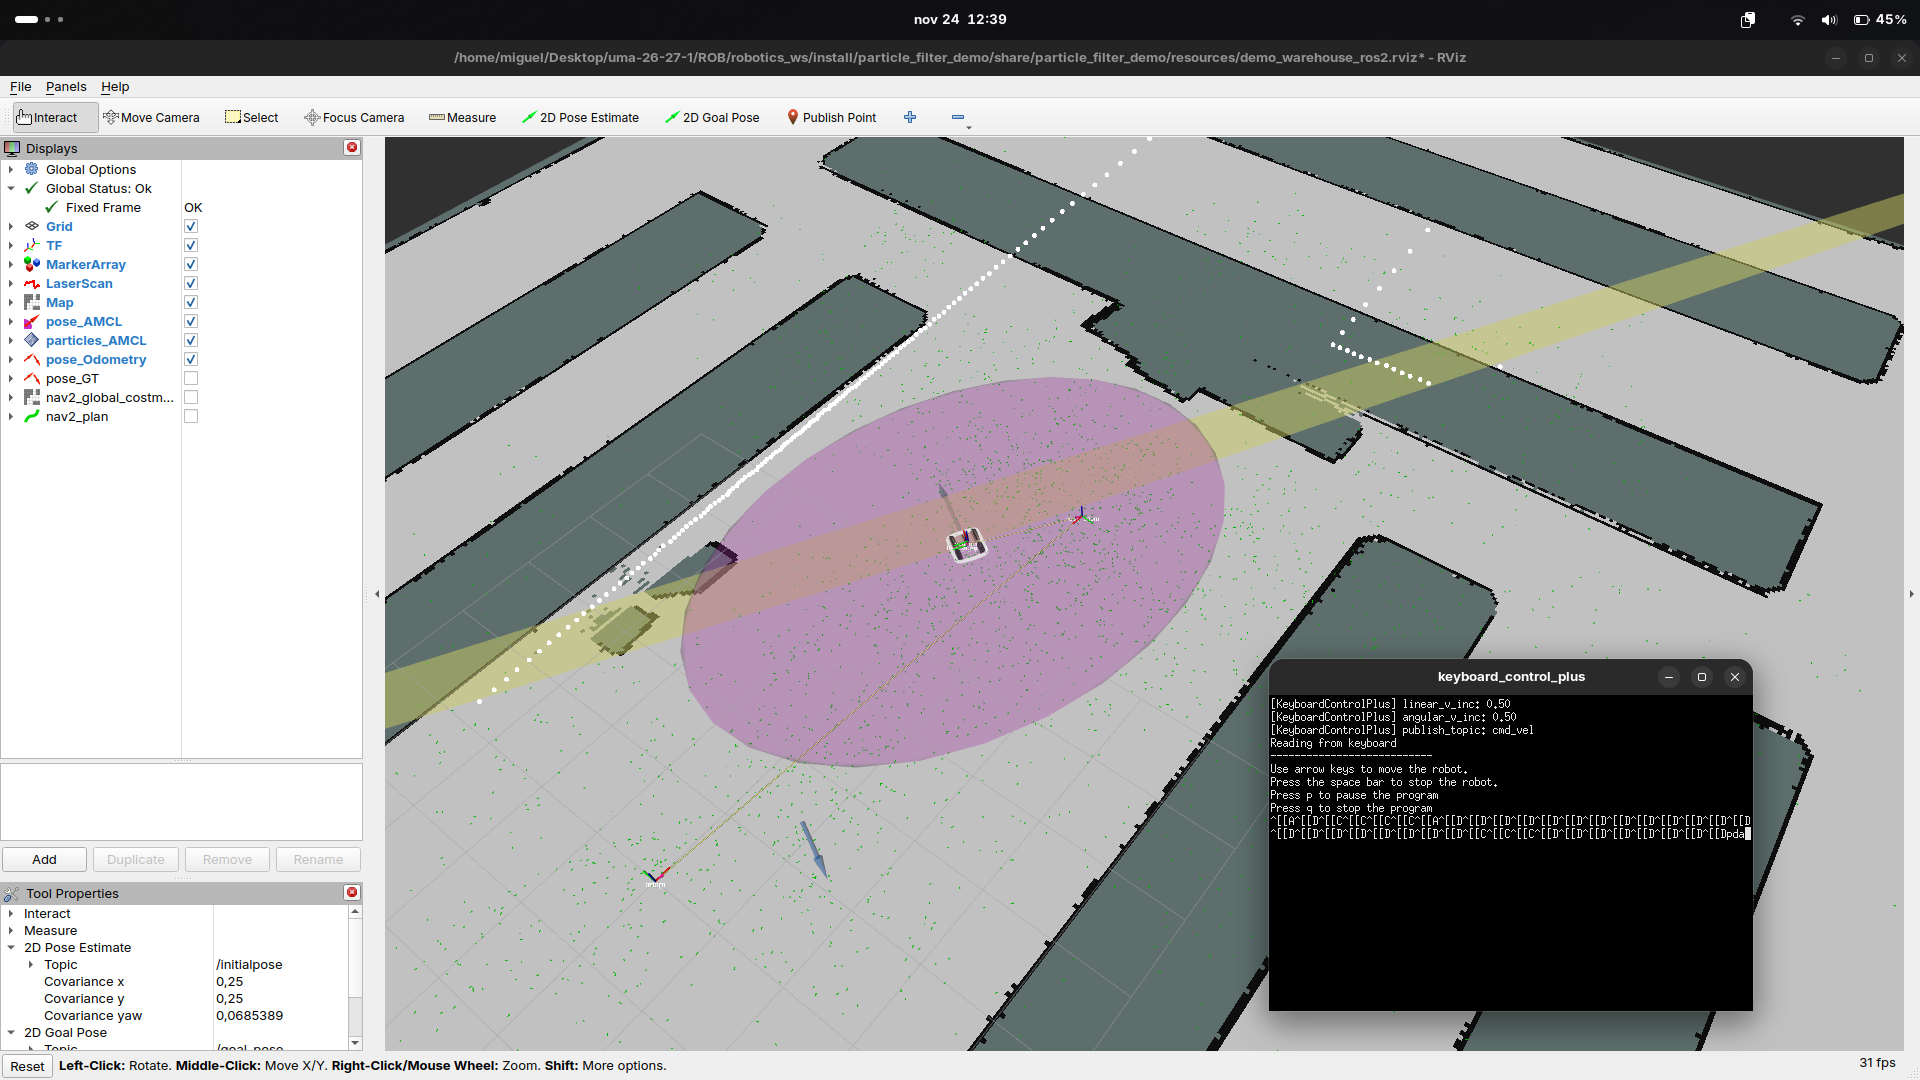


2. From another terminal, list the running nodes. Then, find out the **inputs** and **outputs** of the main node of AMCL, that is, the topics it subscribes to and publishes (*hint: use a `ros2 node` subcommand*). In the table below, which only includes the topics related to localization, write whether each one is an input or an output, its message type and what it is. The first row is an example.

```bash
# TODO: your command here
ros2 node list
ros2 node info /amcl
```

| Input / Output | Topic | Message type | What is it? |
|---|---|---|---|
| Input | `/scanner1` | `sensor_msgs/msg/LaserScan` | The laser scan, that is, the observation $\mathbf{z}_t$ |
| Output | `/amcl_pose` | `geometry_msgs/msg/PoseWithCovarianceStamped` | La pose estimada del robot en el marco map junto con su matriz de covarianza |
| Input | `/initialpose` | `geometry_msgs/msg/PoseWithCovarianceStamped` | Estimación de pose inicial (y covarianza) usada para inicializar o reiniciar el filtro |
| Input | `/map` | `nav_msgs/msg/OccupancyGrid` | El mapa estático de rejilla de ocupación (occupancy grid) del almacén publicado por map_server |
| Output | `/particle_cloud` | `nav2_msgs/msg/ParticleCloud` | El conjunto de partículas ponderadas que representan la distribución de creencia actual |
| Input | `/tf` | `tf2_msgs/msg/TFMessage` | Transformaciones de coordenadas (noisy_odom $\rightarrow$ base_link para la odometría y base_link $\rightarrow$ scanner1 para la geometría del láser) |
| Output | `/tf` | `tf2_msgs/msg/TFMessage` | La transformación de corrección map $\rightarrow$ noisy_odom que ancla la odometría al mapa global |


3. Generate a diagram of the tf tree, as you did in notebook 4.3, and include a **screenshot** of it.

```bash
# TODO: your command here
ros2 run tf2_tools view_frames
```

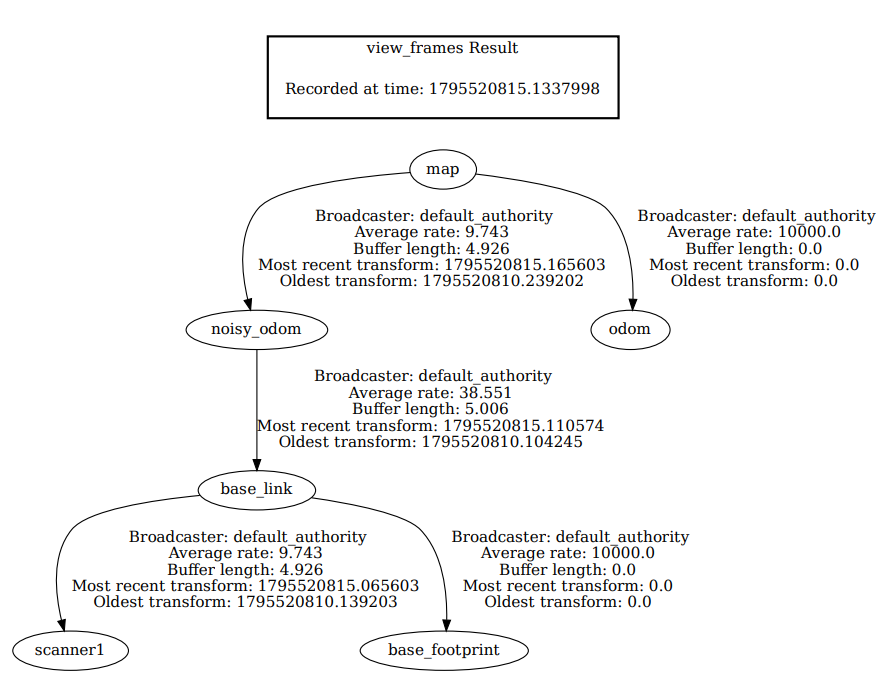


4. In the tree, `map` → `noisy_odom` is published by AMCL, and `noisy_odom` → `base_link` by `odom_simulator`, the node that simulates the odometry. *Note: the frame named `odom` is only used to show the ground truth in RViz2, ignore it.*
   - AMCL estimates the pose of the robot in the map, `map` → `base_link`. Why can't it publish it directly in tf? *Hint: how many parents can a frame have?*
   - What does `map` → `noisy_odom` represent, then? How do we get the pose estimated by AMCL from it?

<p style="margin: 4px 0px 6px 5px; color:blue"><i>

En tf2 de ROS2, los marcos de referencia (frames) deben formar una estructura de árbol estricta en la que cada frame puede tener como máximo un único padre. Como base_link ya tiene a noisy_odom como padre (publicado por odom_simulator), publicar map $\rightarrow$ base_link daría dos padres a base_link y rompería el árbol tf.

map $\rightarrow$ noisy_odom representa la deriva acumulada de la odometría entre el marco global map y el marco noisy_odom que va acumulando error. Obtenemos la pose estimada del robot en el mapa (map $\rightarrow$ base_link) componiendo ambas transformaciones a lo largo del árbol.

</i></p>

## 5.4.3 Odometry vs. AMCL

The demo gives us two estimates of the pose of the robot:

- The **odometry** (`pose_Odometry`, in blue) just integrates the motion of the robot. In terms of the Bayes filter, it only does the **prediction** step, over and over, so its error keeps growing.
- **AMCL** (`pose_AMCL`, in green) does the prediction too, but also the **correction** with each scan, comparing it with the map through the likelihood field, as we did in notebook 5.3.

Let's see how well each of them does, comparing them with the **ground truth** (`pose_GT`, in red), the real pose of the robot, which the simulator knows (Figs. 3 and 4).

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-ground-truth.png" width="1100" alt="">
  <figcaption>Fig. 3. The three poses of the robot in RViz2 right after launching the demo, once <code>pose_GT</code> has been ticked in the <i>Displays</i> panel: they are still together.</figcaption>
</figure>

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-ground-truth-top.png" width="1100" alt="">
  <figcaption>Fig. 4. The same moment as in Fig. 3, seen from above: the three poses coincide.</figcaption>
</figure>

### **<span style="color:green"><b><i>ASSIGNMENT 2: Who knows where the robot is?</i></b></span>**

**What to do?**

1. Enable the `pose_GT` display of RViz2, by ticking its box in the *Displays* panel. Drive the robot for a couple of minutes, turning a lot (for instance, around several rows of shelves, or spinning in place a few times), and include a **screenshot** showing the three poses: the ground truth, the odometry and the AMCL estimate.

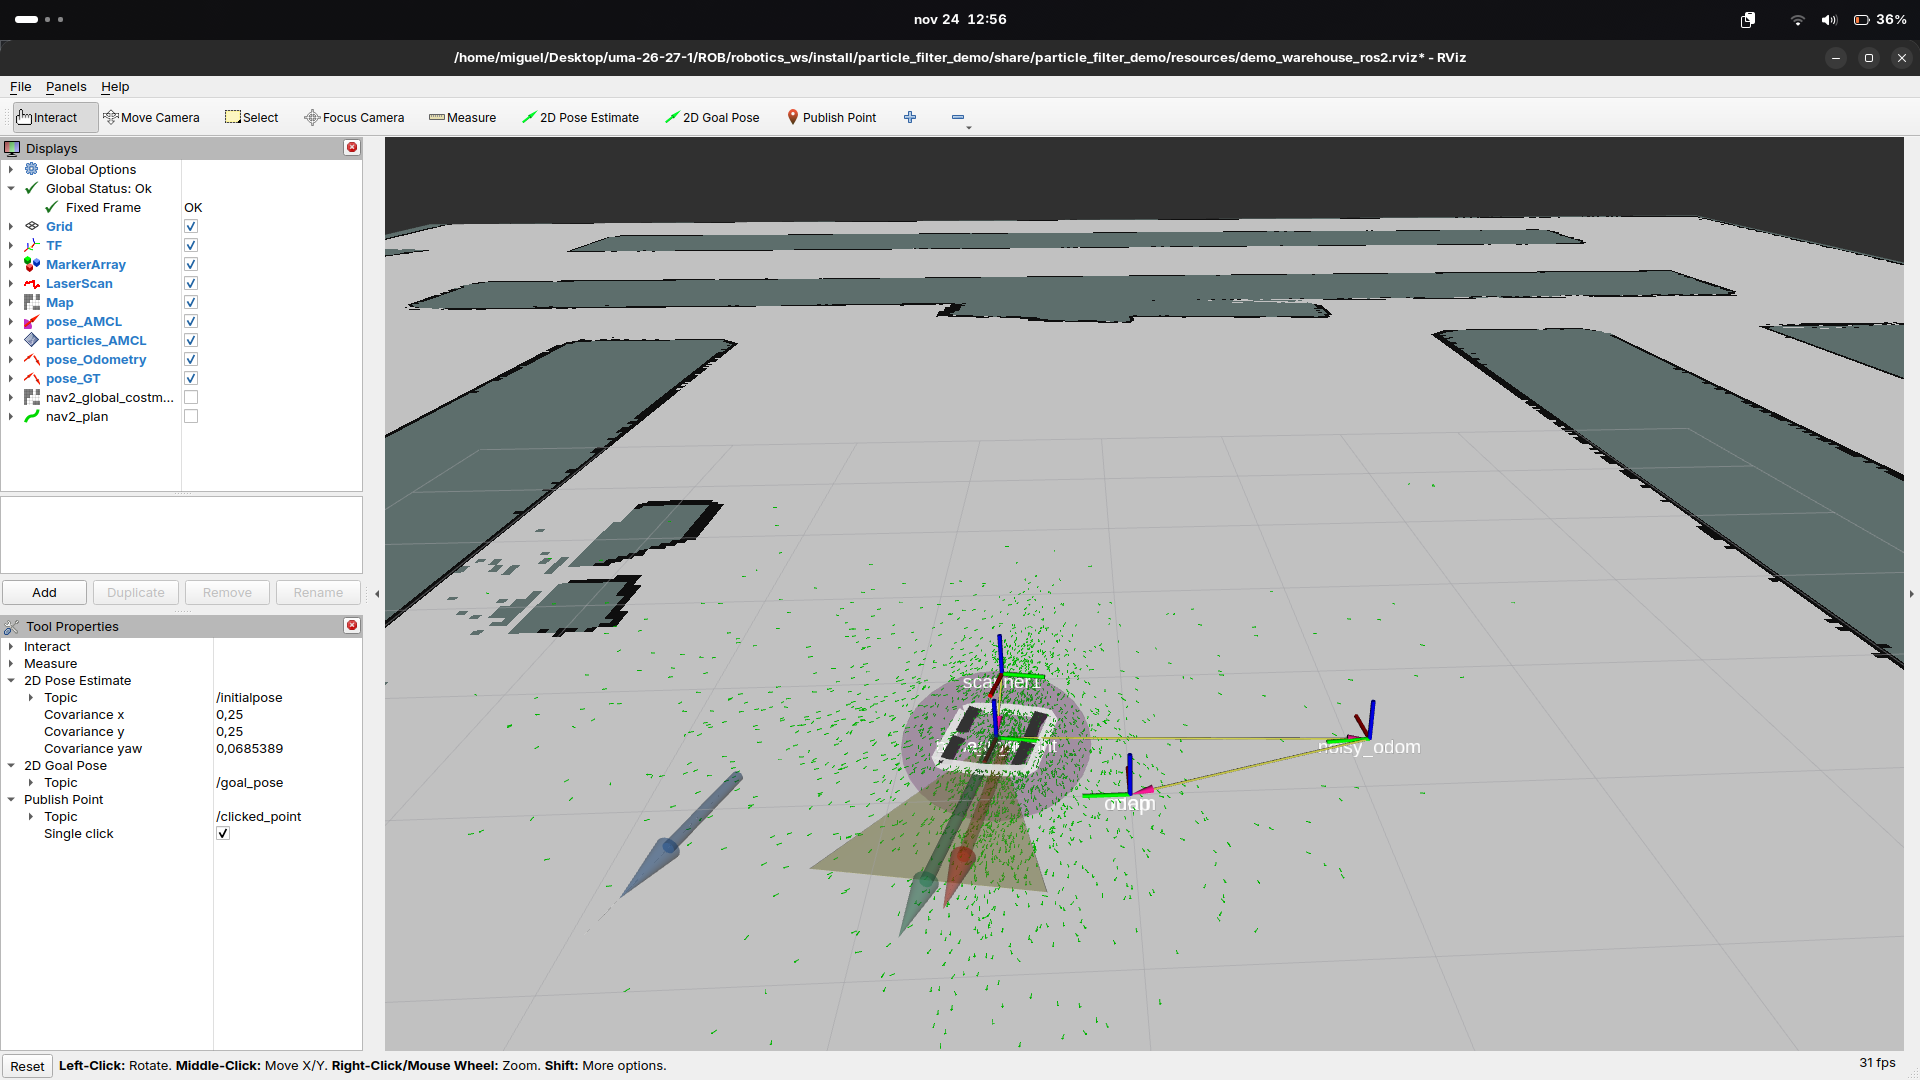


2. Stop the robot (space bar) and print the three poses: the ground truth (`/base_pose_ground_truth`), the odometry (`/noisy_odom`) and the AMCL estimate (`/amcl_pose`). Fill in the table below with their positions and the error of each estimate with respect to the ground truth. *Hint: `--field pose.pose` prints only the pose of a message.*

```bash
# TODO: your command here
ros2 topic echo --once /base_pose_ground_truth --field pose.pose
ros2 topic echo --once /noisy_odom --field pose.pose
ros2 topic echo --once /amcl_pose --field pose.pose

```

| | $x$ (m) | $y$ (m) | Position error (m) |
|---|---|---|---|
| Ground truth | 0.353 | 0.547 | — |
| Odometry | 0.235 | 0.68 | 0.178 |
| AMCL | 0.473 | 0.587 | 0.126 |


3. Why does the error of the odometry keep growing, while the error of AMCL does not?

<p style="margin: 4px 0px 6px 5px; color:blue"><i>

Odometría: Estima el movimiento sumando los comandos de velocidad (bucle abierto). Como no tiene referencias externas, los pequeños deslizamientos de las ruedas se acumulan y el error crece sin límite.

AMCL: Combina esa predicción con un paso de corrección usando un láser 2D y un mapa conocido. Premia las estimaciones (partículas) que coinciden con los obstáculos reales, manteniendo la ubicación precisa y con un error controlado.


</i></p>

## 5.4.4 The particles

AMCL publishes its particles in the `/particle_cloud` topic, whose messages are of type `nav2_msgs/msg/ParticleCloud`. In RViz2, the `particles_AMCL` display draws each particle as a green arrow (Fig. 5): if they are hard to see, make them longer with its *Min Arrow Length* and *Max Arrow Length* options. Two details are worth knowing:

- AMCL does not update the filter with every scan, but only when the robot has moved more than 5 cm or turned more than 0.05 rad, about 3° (values set in the configuration of this demo, see section 5.4.7). So, **the particles are only published while the robot moves**: keep it moving when you print them.
- The *Adaptive* of AMCL: the number of particles $M$ is not fixed, but it is adapted after each update, between 500 and 5000 (again, values set in the configuration of this demo), using **KLD-sampling**. Roughly speaking, it uses few particles when they are concentrated in a small region, and many when they are spread out, so the computational effort follows the uncertainty.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-particles.png" width="1100" alt="">
  <figcaption>Fig. 5. The particles of AMCL around the robot in RViz2, with their arrows made longer in the <code>particles_AMCL</code> display.</figcaption>
</figure>

### **<span style="color:green"><b><i>ASSIGNMENT 3: Looking at the particles</i></b></span>**

**What to do?**

1. While the robot moves, print a single message of `/particle_cloud` without its long arrays (*hint: `ros2 topic echo` has a `--no-arr` option, which prints only the length of the arrays*). How many particles $M$ is AMCL using? Why that number?

```bash
# TODO: your command here
ros2 topic echo --once --no-arr /particle_cloud
```

<p style="margin: 4px 0px 6px 5px; color:blue"><i>501. Esto se debe a que AMCL emplea KLD-sampling para adaptar dinámicamente el número de partículas entre min_particles (500) y max_particles (5000) en función de la dispersión espacial de la creencia. Cuando las partículas están muy concentradas en torno a la pose real, ocupan muy pocas celdas del espacio de estados, por lo que KLD-sampling reduce $M$ hasta el mínimo configurado de 500.</i></p>


2. Now print the particles themselves, and look at their weights. Are they different? Why do you think this happens? *Hint: the message is very long, so pipe the output of `ros2 topic echo` into `head -c 2000` to see only its first 2000 characters.*

```bash
# TODO: your command here
ros2 topic echo --once /particle_cloud | head -c 2000
```

<p style="margin: 4px 0px 6px 5px; color:blue"><i>

No, todas las partículas tienen exactamente el mismo peso (igual a $1/M$, por ejemplo 0.002 cuando $M = 500$). Esto ocurre porque /particle_cloud se publica después de haber ejecutado el paso de remuestreo (resampling): las partículas se extrajeron con probabilidad proporcional a sus pesos de importancia y, tras remuestrear, a todas las partículas resultantes se les asignó un peso uniforme ($1/M$) para el siguiente ciclo.

</i></p>

## 5.4.5 The uncertainty of the estimate

AMCL publishes its estimate in `/amcl_pose`: the pose, plus its **covariance**, which AMCL computes from its particles, as `current_estimation()` did in notebook 5.3. RViz2 draws it as the magenta ellipse (position) and the yellow cone (orientation) of `pose_AMCL`, both clearly visible in Fig. 5.

Since ROS represents poses in 3D, this covariance is a $6 \times 6$ matrix over $(x, y, z, \text{roll}, \text{pitch}, \text{yaw})$, stored as a list of 36 numbers, row by row. For our robot, the interesting ones are the variances of $x$, $y$ and the yaw $\theta$: the elements 0 ($\sigma_x^2$), 7 ($\sigma_y^2$) and 35 ($\sigma_\theta^2$) of the list.

### **<span style="color:green"><b><i>ASSIGNMENT 4: Reading the covariance</i></b></span>**

**What to do?**

1. Print a single message of `/amcl_pose`, and compute the standard deviations $\sigma_x$, $\sigma_y$ (in meters) and $\sigma_\theta$ (in degrees). Do they match the size of the ellipse and the cone in RViz2?

```bash
# TODO: your command here
ros2 topic echo --once /amcl_pose
```

<p style="margin: 4px 0px 6px 5px; color:blue"><i>

$\sigma_x = \sqrt{0.0421} = 0.205 m$

$\sigma_y = \sqrt{0.00498} = 0.0706 m$

$\sigma_{\theta} = \sqrt{0.0226} = 0.1503 · 180/\pi = 8.61^\circ$


Sí. Cuando el robot está bien localizado, $\sigma_x$ y $\sigma_y$ son de apenas unos centímetros y $\sigma_\theta$ de unos pocos grados, lo que corresponde con la pequeña elipse de incertidumbre magenta alrededor del robot..

</i></p>

## 5.4.6 Global localization and the kidnapped robot

So far, AMCL has been solving the easiest localization problem of notebook 5.0, **position tracking**: it starts knowing the initial pose of the robot, $[0, 0, 0]^T$, where the robot starts. But, unlike the EKF, a particle filter can represent multimodal beliefs, so it can also tackle the two harder ones:

- **Global localization**: the initial pose is unknown. AMCL spreads the particles over the free space of the map, and lets the scans discard the wrong hypotheses (Fig. 6).
- **The kidnapped robot**: the robot is moved somewhere else without the filter knowing it, so all the particles are wrong. To recover, when the scans suddenly fit the map much worse than usual, AMCL **injects random particles** all over the map. This is the *Augmented MCL* algorithm of the book *Probabilistic Robotics*, by S. Thrun, W. Burgard and D. Fox.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-global-localization.png" width="1100" alt="">
  <figcaption>Fig. 6. Global localization with AMCL in the warehouse of the demo, from the particles published in <code>/particle_cloud</code> while the robot moved. (a) Right after the reinitialization, the M = 5000 particles cover the whole map. (b) A few updates later, only those where the scan fits the map survive, grouped in clusters. (c) A few hypotheses remain, and their number drops. (d) The particles converge into a single cluster, at the true pose of the robot (in red).</figcaption>
</figure>

### **<span style="color:green"><b><i>ASSIGNMENT 5: Getting lost, and found</i></b></span>**

**What to do?**

1. **Global localization**. AMCL offers a service, `/reinitialize_global_localization`, that spreads all its particles over the map. Find out its type, and call it. *Hint: `ros2 service type` and `ros2 service call`.* Then, drive the robot slowly, avoiding the obstacles, until the particles converge, and include **screenshots** of RViz2 right after starting to drive and once they have converged. Did it converge to the right place?

```bash
# TODO: your command here
ros2 service type /reinitialize_global_localization
ros2 service call /reinitialize_global_localization std_srvs/srv/Empty
```

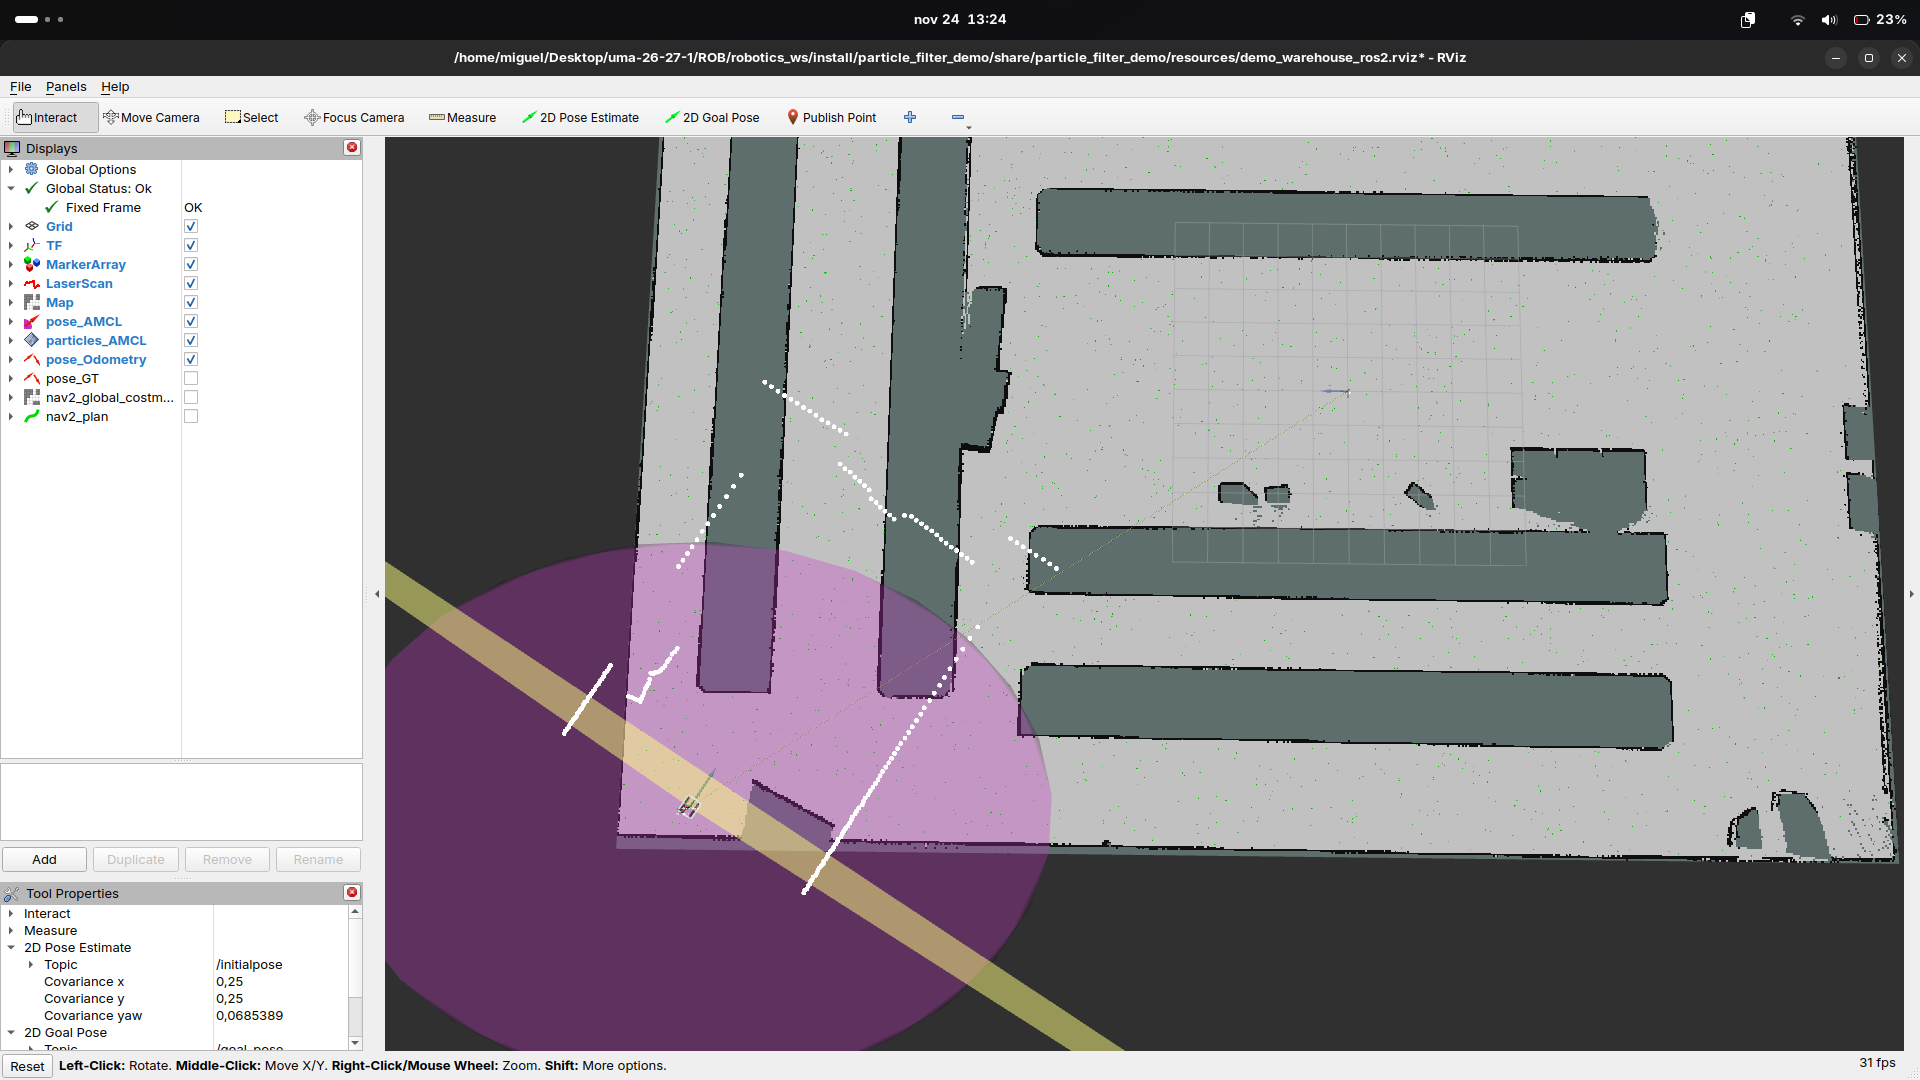

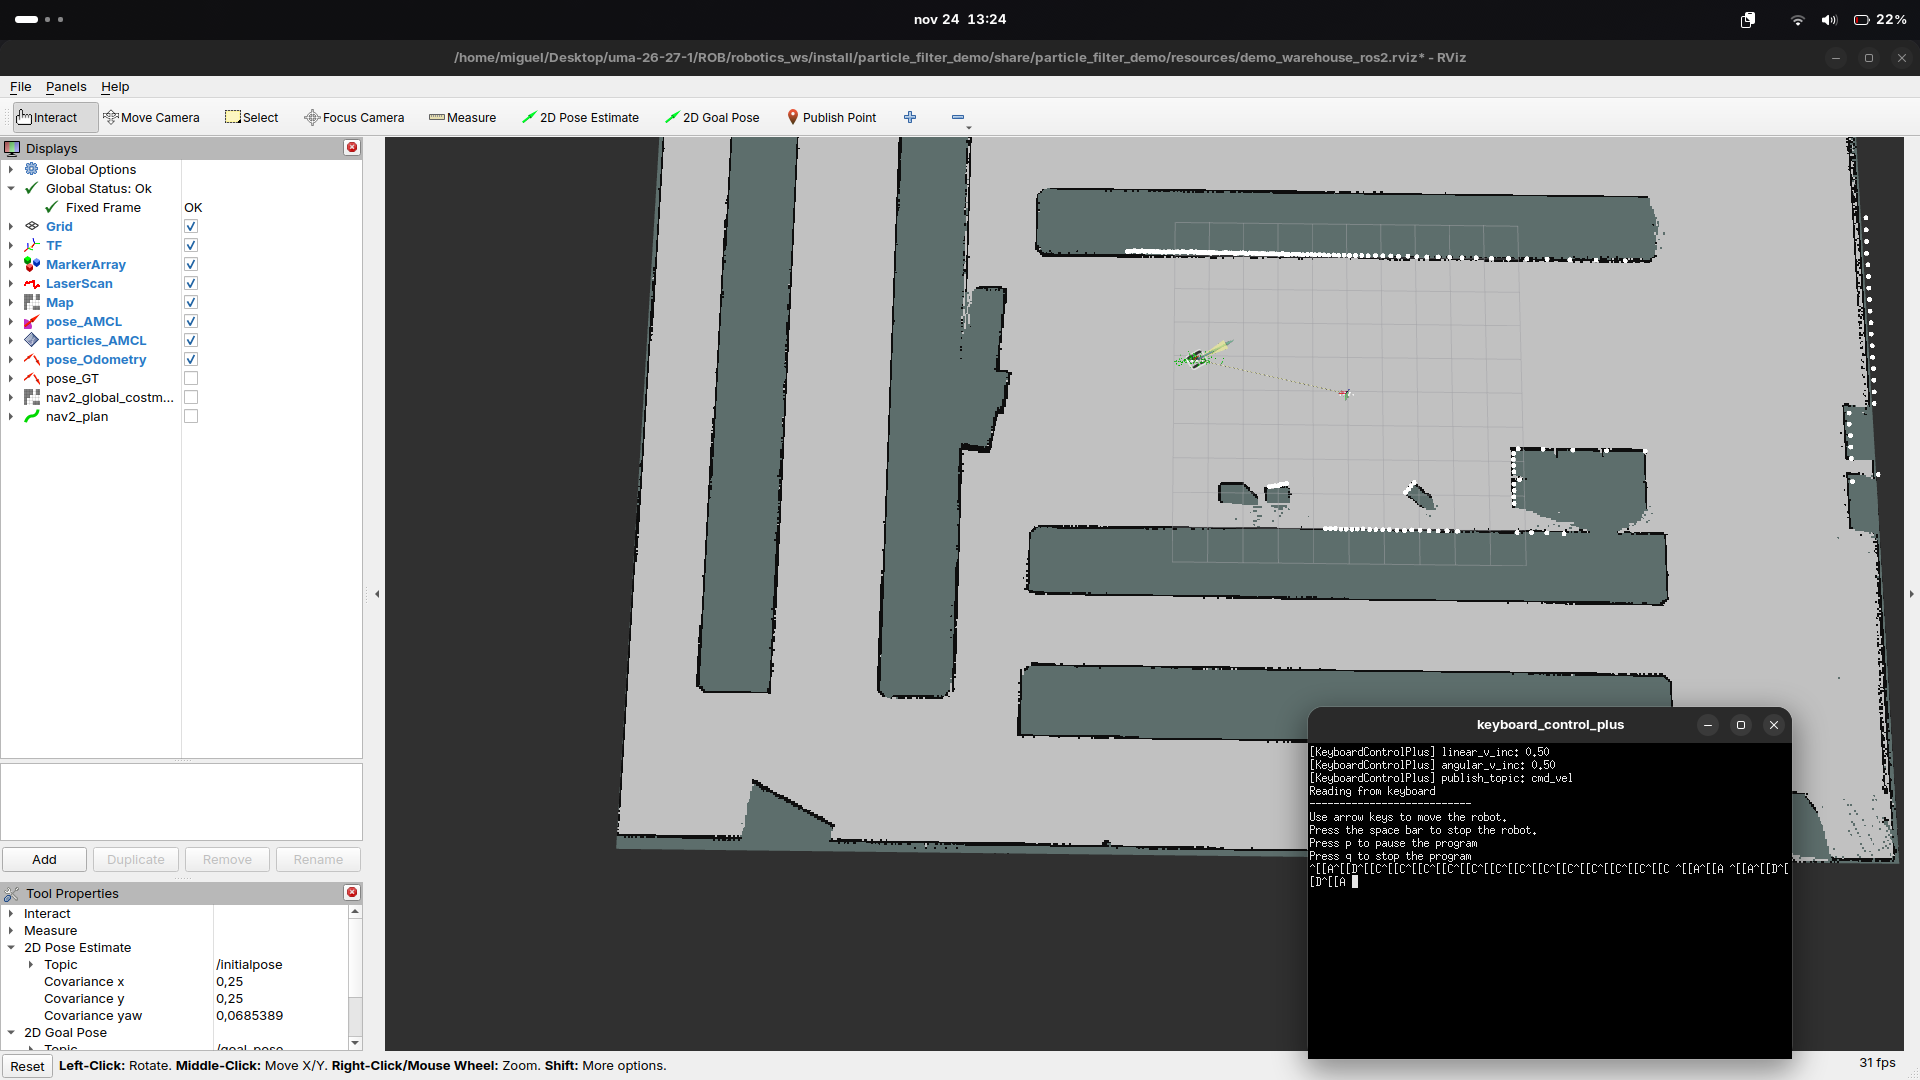

Si converge, vemos como desaparece la elipse.


2. **The kidnapped robot**. With AMCL well localized, use the *2D Pose Estimate* tool of the toolbar of RViz2 (Fig. 7) to tell AMCL that the robot is somewhere else, e.g. in another aisle. Then, drive the robot, and include **screenshots** of RViz2 right after the kidnapping and a few seconds later. Does AMCL recover? How long does it take?

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-4-rviz-tools.png" width="1100" alt="">
  <figcaption>Fig. 7. The tools of the toolbar of RViz2 used in this notebook: <i>2D Pose Estimate</i>, to give AMCL the pose of the robot, and <i>2D Goal Pose</i>, to send a navigation goal to Nav2.</figcaption>
</figure>

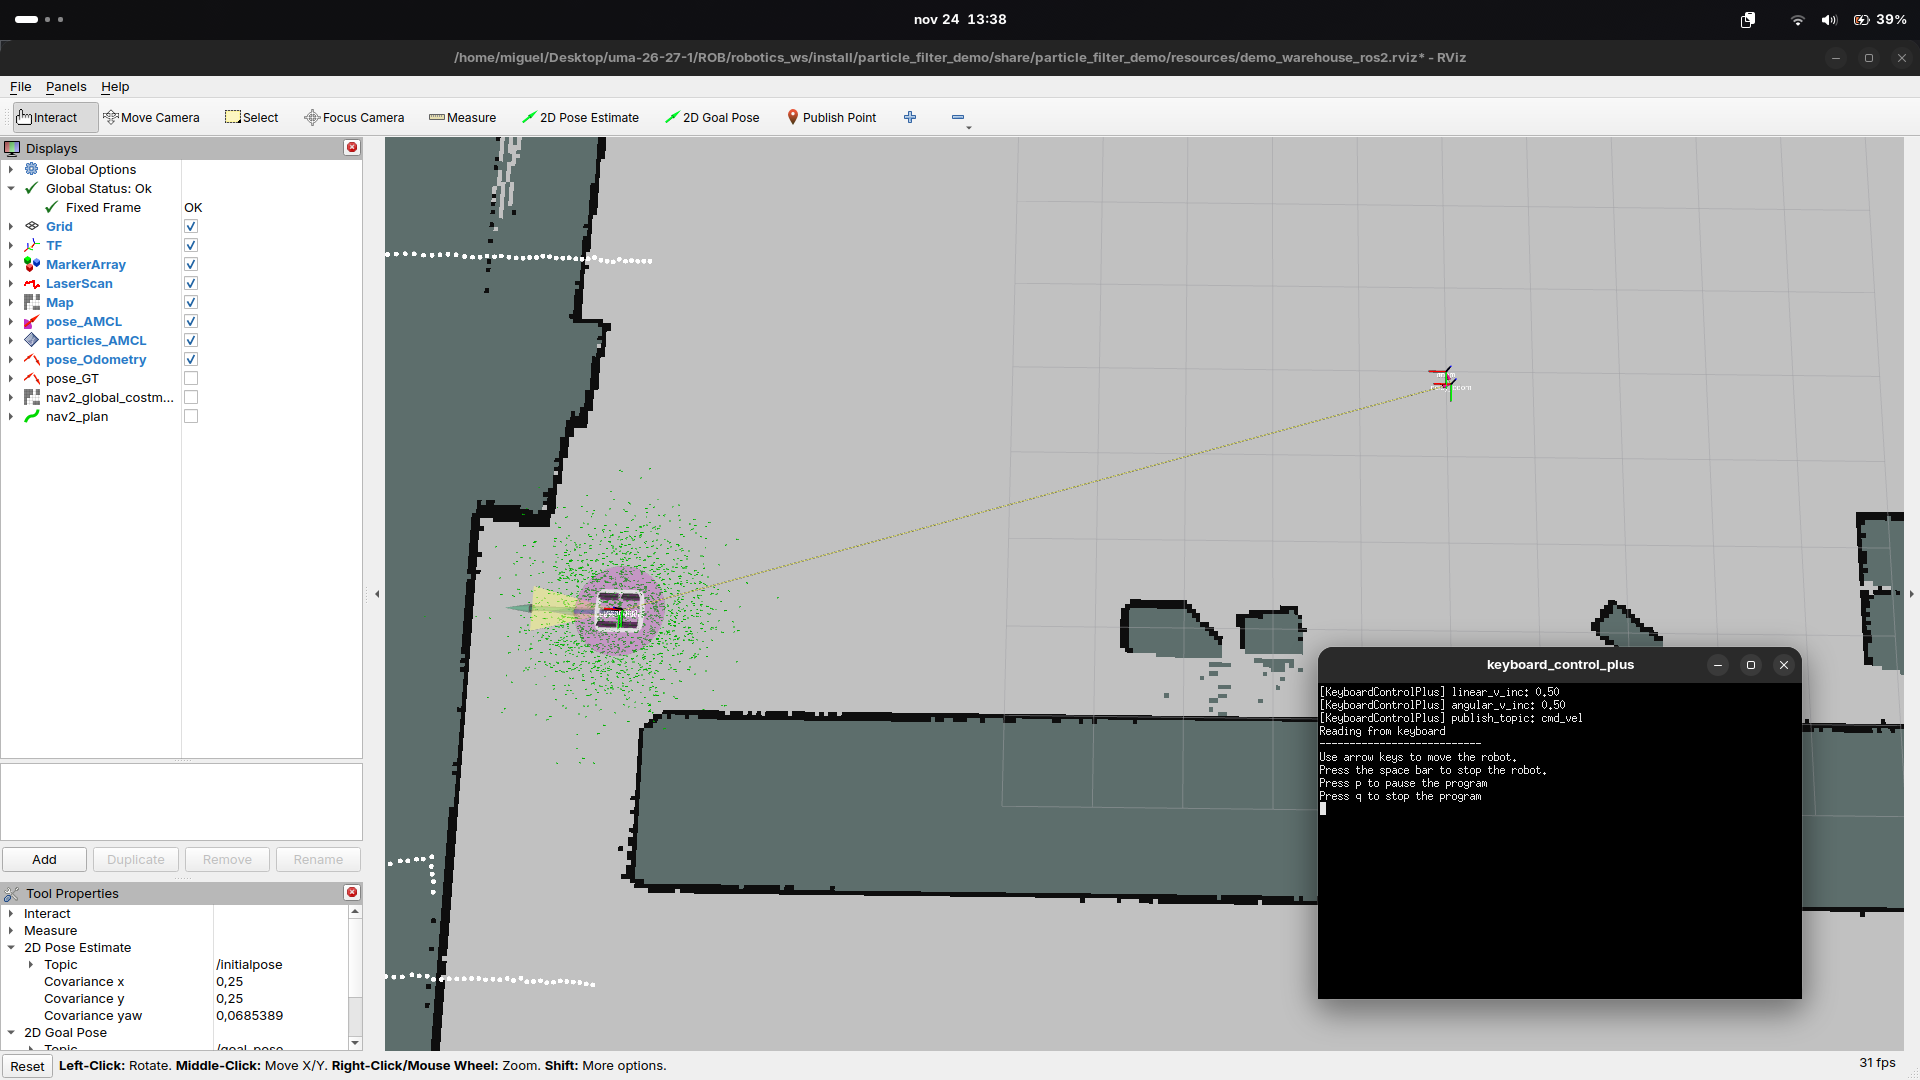

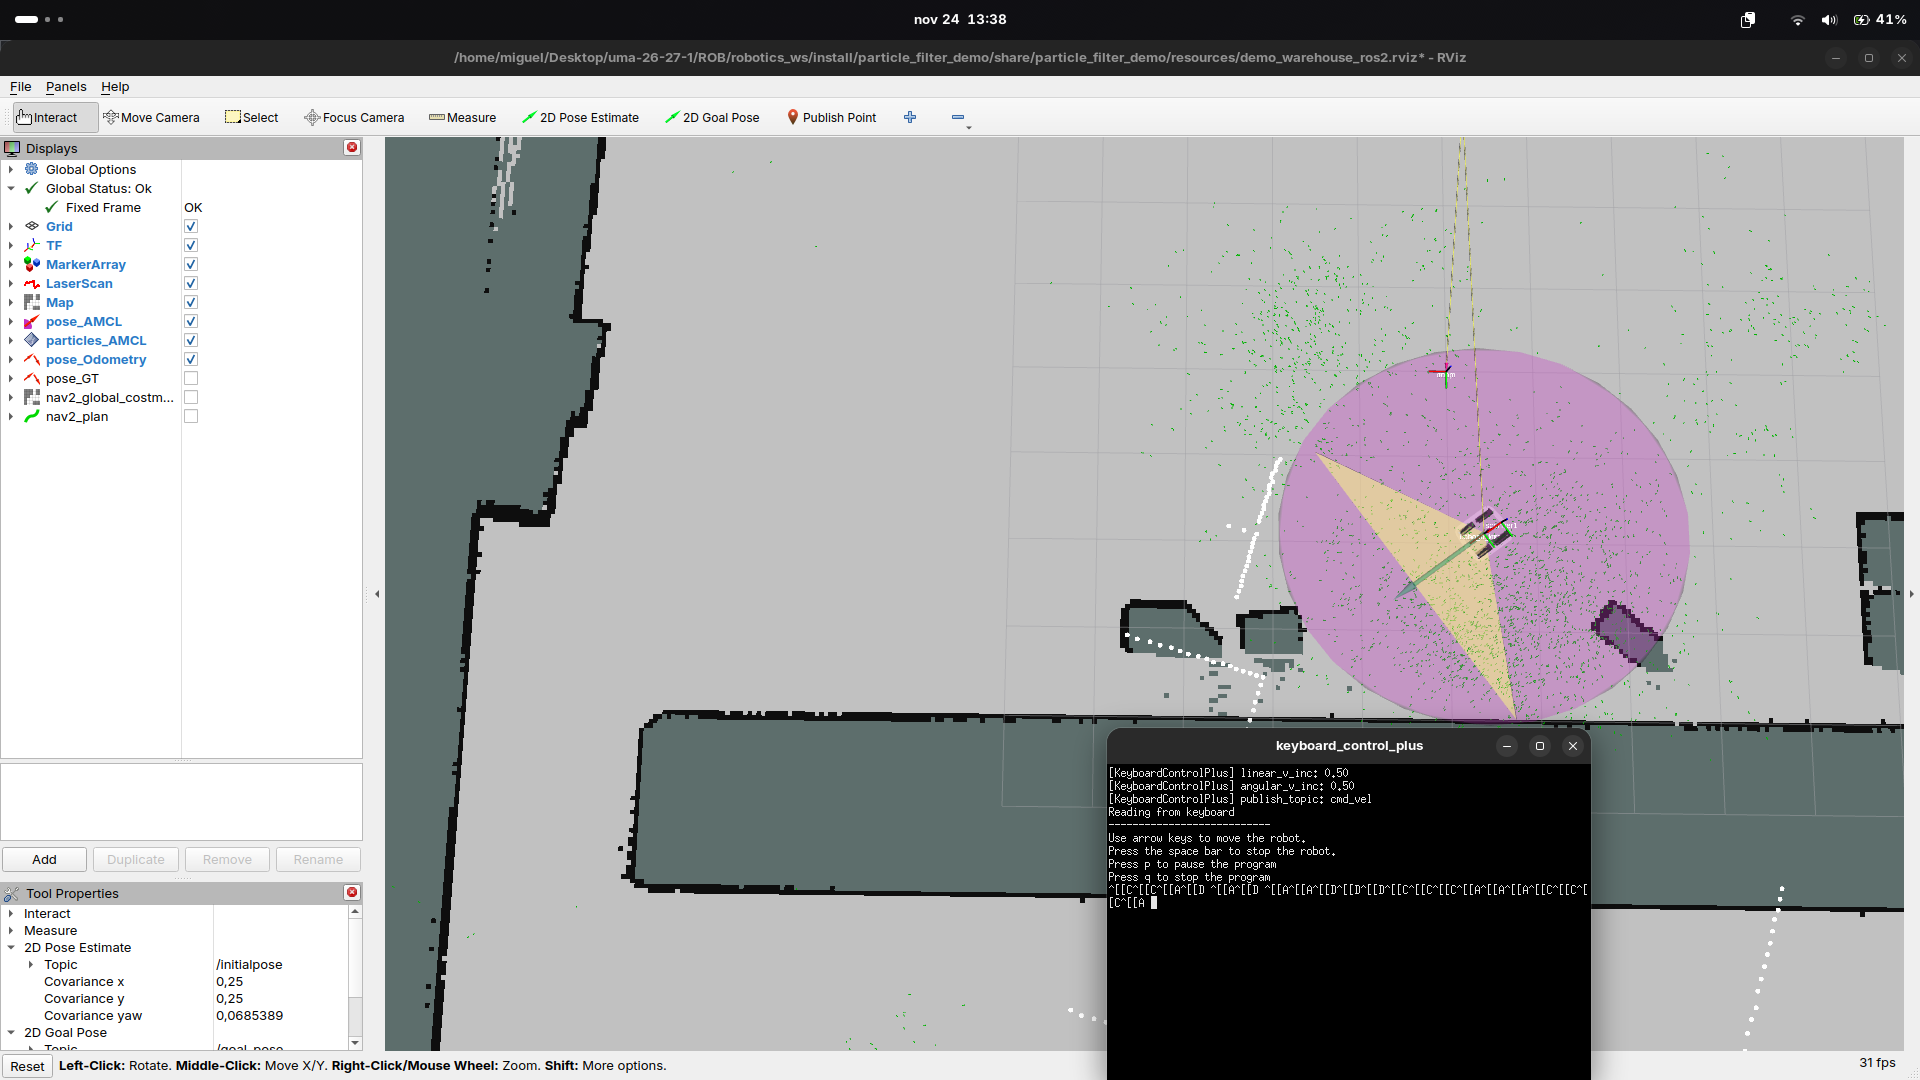

Sí, AMCL se recupera, lo que si es verdad es que ha tardado bastante más.

## 5.4.7 How many particles?

AMCL has quite a few parameters, all of them in `robotics_ws/src/particle_filter_demo/resources/params.yaml` (the [Nav2 documentation](https://docs.nav2.org/jazzy/configuration_and_development/configuration_guide/others/configuring_amcl/) describes them). We will play with two of them: `min_particles` and `max_particles` (500 and 5000), the limits of the number of particles $M$ for KLD-sampling (section 5.4.4).

You can change a parameter with `ros2 param set` while AMCL runs. Note that, when the number of particles changes, AMCL restarts the filter at the initial pose: give it the right pose with *2D Pose Estimate* afterwards.

### **<span style="color:green"><b><i>ASSIGNMENT 6: How many particles do we need?</i></b></span>**

**What to do?**

1. Reduce the number of particles a lot, setting `min_particles` to 10 and `max_particles` to 20, and give AMCL the right pose. Drive the robot for a while, turning several times, and watch `pose_AMCL` and `pose_GT`. Is the localization better or worse than with the default values? Does the ellipse reflect the actual error?

```bash
# TODO: your command here
ros2 param set /amcl min_particles 10
ros2 param set /amcl max_particles 20
```

<p style="margin: 4px 0px 6px 5px; color:blue"><i>

Con 10–20 partículas ocurre empobrecimiento de partículas: no cubren bien el espacio $(x, y, \theta)$ y, al girar, casi ninguna cae cerca de la pose real, haciendo que pose_AMCL dé saltos o pierda el rastro de pose_GT.

No. Al colapsar las pocas partículas sobre una sola hipótesis tras el remuestreo, su varianza es artificialmente baja y RViz2 dibuja una elipse diminuta (falso exceso de confianza) aunque el error real sea grande.</i></p>

### <font color="blue"><b><i>Thinking about it</i></b></font>

Having played with AMCL, **answer the following questions**:

- Right after starting, the odometry may be as accurate as AMCL, or even more. Why is AMCL needed, then?

  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Porque la odometría es en bucle abierto y acumula error sin límite con el tiempo, además de no resolver la localización global ni los secuestros. AMCL usa el láser y el mapa para corregir continuamente esa deriva y mantener el error acotado.</i></p>

- The odometry of this demo drifts a lot when turning, and yet AMCL keeps the robot well localized. Would it work equally well with no odometry at all? And with no laser scanner?

  <p style="margin: 4px 0px 6px 5px; color:blue"><i>

  Sin odometría: Mucho peor; dependería de un modelo de paseo aleatorio muy ruidoso, necesitaría muchas más partículas y fallaría fácilmente en giros o pasillos largos.

  Sin escáner láser: No localizaría en absoluto y degeneraría en pura odometría, al no tener observaciones ($\mathbf{z}_t$) para corregir la deriva.</i></p>

- The warehouse of the demo has many places that look alike. What could you do to make global localization more reliable in such an environment?

  <p style="margin: 4px 0px 6px 5px; color:blue"><i>

    Aumentar max_particles (p. ej., a 20.000) para muestrear el mapa con mayor densidad.

    Romper la simetría añadiendo obstáculos asimétricos o marcadores visuales (como AprilTags).

    Usar un LiDAR de mayor alcance (que vea las paredes exteriores) o fusionar sensores adicionales.

    Explorar hacia intersecciones o extremos de pasillo en lugar de avanzar solo en línea recta.</i></p>

### **<span style="color:green"><b><i>OPTIONAL: More particles for global localization</i></b></span>**

In Assignment 5, global localization often converged to a wrong place. Set `max_particles` to 20000 and `min_particles` back to 500, and repeat it a few times. Does it converge to the right place more often? What is the price to pay?

```bash
# TODO: your command here
ros2 param set /amcl max_particles 20000
ros2 param set /amcl min_particles 500
ros2 service call /reinitialize_global_localization std_srvs/srv/Empty
```

<p style="margin: 4px 0px 6px 5px; color:blue"><i>Sí, al muestrear $(x, y, \theta)$ cuatro veces más densamente acierta con mucha mayor frecuencia. El precio a pagar es un consumo de CPU y una latencia significativamente mayores al inicio, hasta que KLD-sampling reduce la nube de partículas.</i></p>

### **<span style="color:green"><b><i>OPTIONAL: Navigating with Nav2</i></b></span>**

Knowing where the robot is, is usually not a goal in itself, but what we need to make it move to where we want. That is the job of the rest of **[Nav2](https://docs.nav2.org/)**: a *planner* computes a path to the goal over a costmap built from the map, and a *controller* sends the velocity commands to follow it, while AMCL tells them where the robot is. The demo can also launch these navigation servers:

```bash
ros2 launch particle_filter_demo demo_warehouse.launch.py nav2:=True
```

Their parameters are in `robotics_ws/src/particle_filter_demo/resources/nav2_params.yaml`. In RViz2, enable the displays `nav2_global_costmap` (the costmap used by the planner) and `nav2_plan` (the planned path). Before sending a goal, **press `p` in the window of `keyboard_control`** to pause it: otherwise it keeps publishing velocity commands, which fight those of Nav2.

1. Use the *2D Goal Pose* tool of the toolbar of RViz2 (Fig. 7) to send the robot to the other side of the warehouse, and include a **screenshot** of the path. Does the robot get there, even though its odometry drifts? Why? *Note: you can also send a goal from a terminal, e.g.:*

```bash
ros2 action send_goal /navigate_to_pose nav2_msgs/action/NavigateToPose "{pose: {header: {frame_id: map}, pose: {position: {x: 9.0, y: -7.0}, orientation: {w: 1.0}}}}"
```

2. While the robot navigates, *kidnap* AMCL with the *2D Pose Estimate* tool, as in Assignment 5. What happens with the navigation?

Write your answers below.

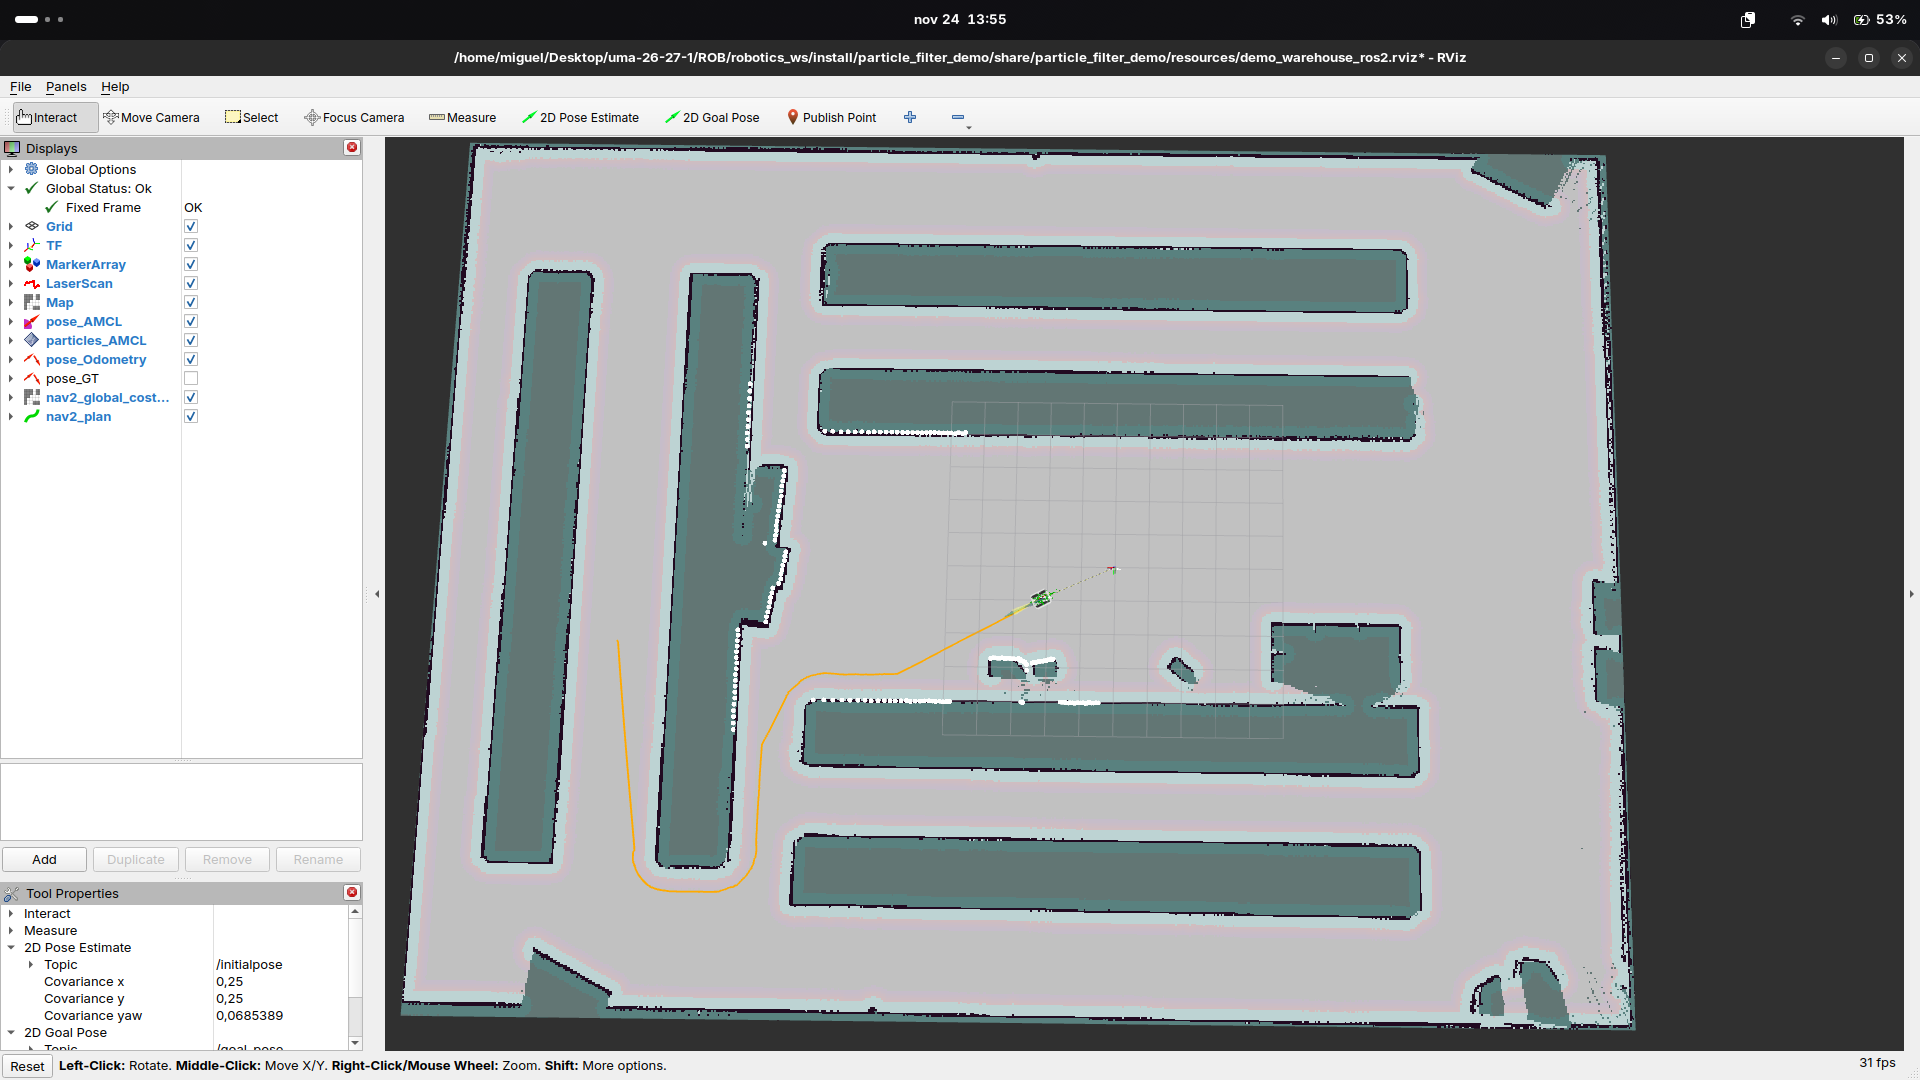

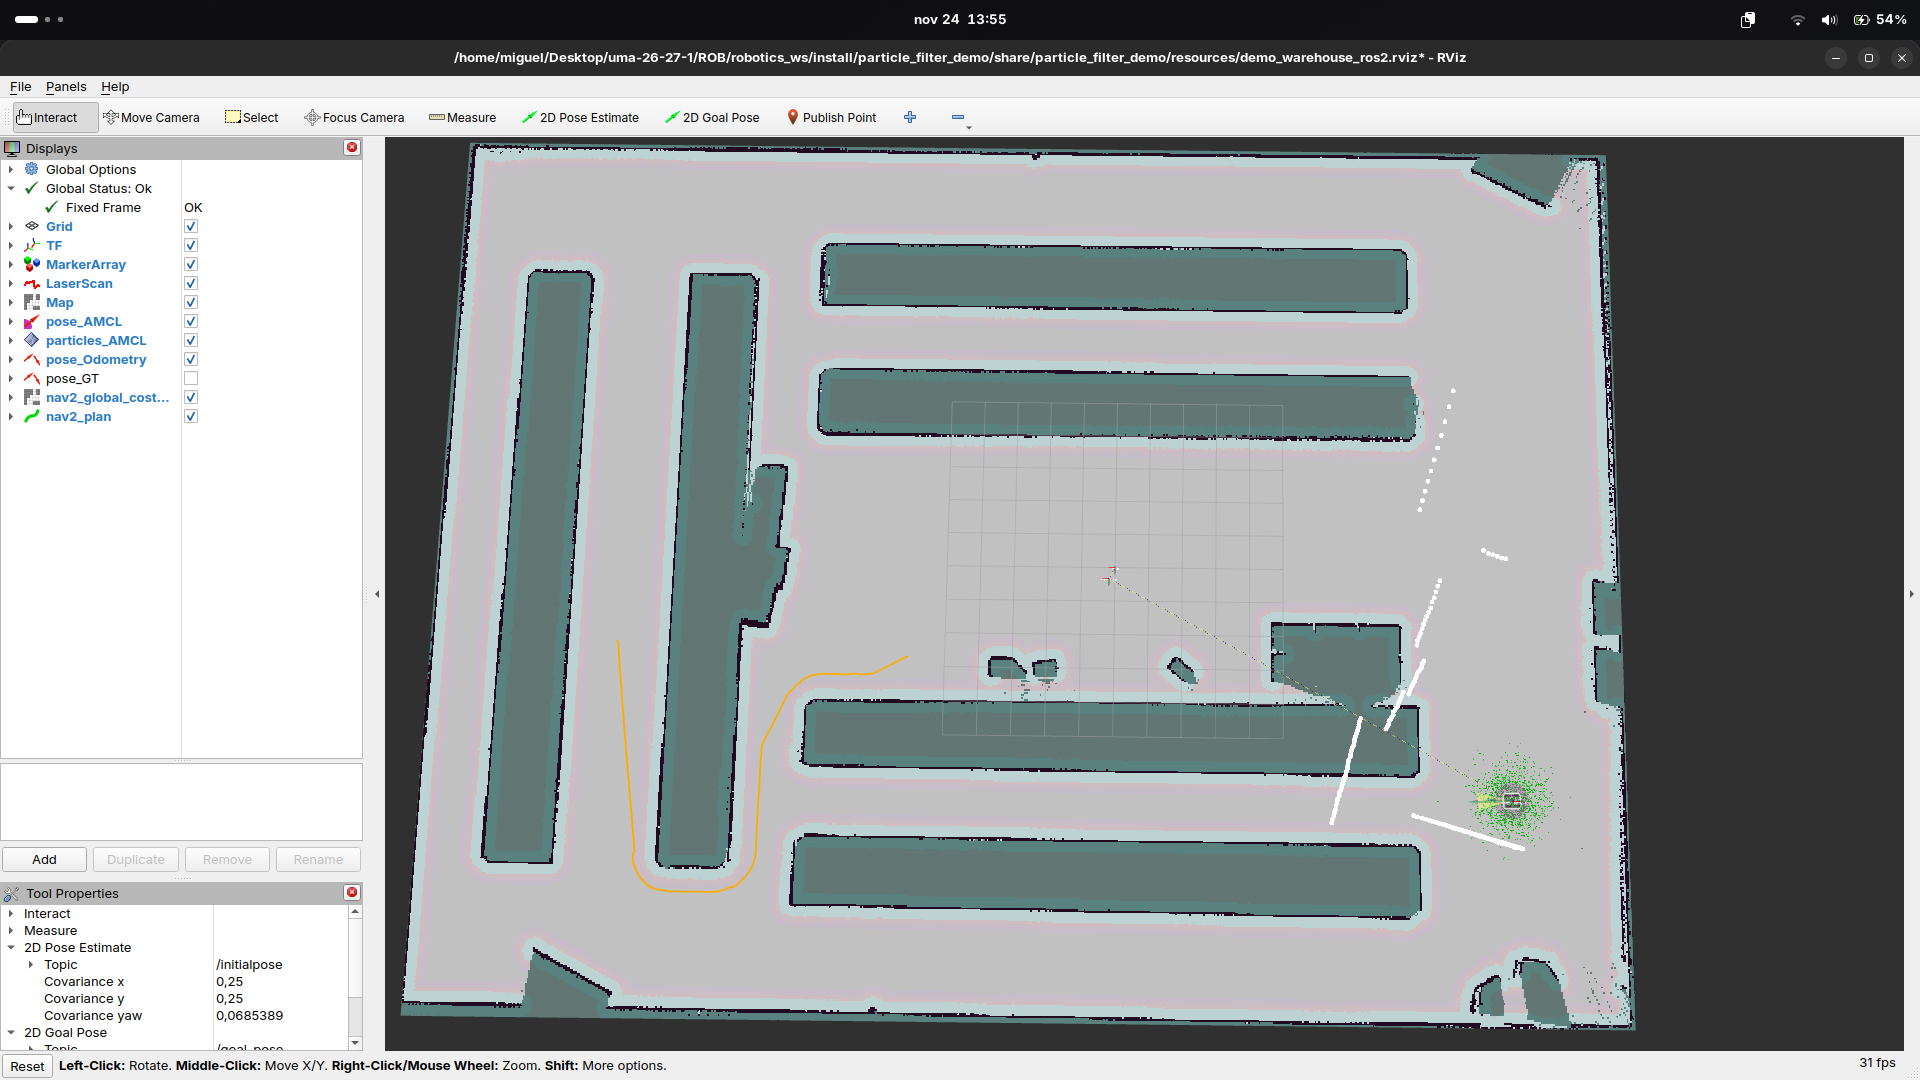

Sí. Nav2 planifica y controla en el marco map usando map $\rightarrow$ noisy_odom $\rightarrow$ base_link, y AMCL actualiza continuamente map $\rightarrow$ noisy_odom para compensar la deriva de la odometría.


Nav2 asume la pose falsa y recalcula la ruta desde allí, pero al proyectar el láser real sobre esa ubicación equivocada detecta una posible colisión con los obstáculos del mapa y detiene el robot por seguridad (o entra en comportamientos de recuperación/aborta la meta). Al quedar el robot quieto, AMCL deja de actualizarse y no puede re-localizarse hasta que el robot vuelve a moverse.

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Gemini Google</i></p>
- **What I asked AI to help with (bullets):**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>

    - Verificar los comandos CLI de ROS2 Jazzy (ros2 node info, ros2 topic echo, ros2 service call, ros2 param set, tf2_tools view_frames).

    - Comprobar los nombres exactos de los tópicos de entrada/salida y los tipos de mensaje de AMCL en Nav2.

    - Estructurar y refinar las explicaciones teóricas sobre la composición de transformaciones tf2, el muestreo KLD-sampling, Augmented MCL y el empobrecimiento de partículas.</i></p>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Que comandos se usa para este apartado</i></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>

    - Mantuve: Los comandos de ROS2, la tabla de tópicos, las explicaciones teóricas y las fórmulas paso a paso.
    - Cambié / Añadí: Inserté mis propias capturas de pantalla de RViz2 y los valores numéricos específicos de pose y covarianza obtenidos al ejecutar la simulación en mi equipo.</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this mobile robotics lab notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant ROS2 concepts and tools used, not particular commands or topics),
- one on how to improve the work (most critical aspect: limitations, parameter choices, robustness, possible mistakes).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Los ciclos bayesianos de predicción-corrección acotan el error de localización, evitando la deriva acumulativa de odometría.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>KLD-sampling adapta dinámicamente las partículas y la inyección aleatoria resuelve el secuestro del robot.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Los árboles TF2 de ROS2 componen limpiamente las correcciones mapa-odometría con las transformaciones odometría-base.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Las visualizaciones de covarianza en RViz2 y el ajuste dinámico diagnostican el empobrecimiento de partículas.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Los pasillos simétricos provocan convergencias falsas; aumentar las partículas máximas mejora la localización global.</i></p>

Finally, **do you agree with them?**, **would you have selected others?**
    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Sí, estoy de acuerdo con ellos. Los dos puntos de teoría resumen las ventajas algorítmicas clave de AMCL frente al MCL básico y la odometría pura; los dos de práctica reflejan con precisión cómo se usan tf2 y RViz2 para diagnosticar el filtro en ROS2; y el punto de mejora identifica la principal limitación observada en el mapa del almacén (el aliasing perceptual en pasillos simétricos). Como complemento, añadiría también la importancia de ajustar los parámetros recovery_alpha_slow y recovery_alpha_fast para una recuperación fiable ante secuestros.</i></p>